In [9]:
import sys
print(sys.executable)
print(sys.prefix)

/opt/anaconda3/envs/tumors/bin/python
/opt/anaconda3/envs/tumors


In [10]:
log_file = "log_eden.tsv"

In [11]:
import pandas as pd
import dendropy

# Read IDs as strings to avoid converting missing-parent columns to floats.
df = pd.read_csv(
    log_file,
    sep = '\t',
    dtype={"id": "string", "parent_id": "string", "birth_date": "int", "death_date": "int"},
)

if df["id"].isna().any() or not df["id"].is_unique:
    raise ValueError("Each id must be unique and nonmissing.")

# The root is the individual whose parent_index is blank.
root_ids = df.loc[df["parent_id"].isna(), "id"].tolist()

if len(root_ids) != 1:
    raise ValueError("Expected exactly one root with a blank parent_index.")

# Create every node before connecting them: CSV row order does not matter.
nodes = {
    cell_id: dendropy.Node(label=cell_id)
    for cell_id in df["id"]
}

# Attach each individual to its parent.
for row in df.itertuples(index=False):
    if pd.isna(row.parent_id):
        continue

    if row.parent_id not in nodes:
        raise ValueError(f"Missing parent: {row.parent_id}")

    nodes[row.parent_id].add_child(nodes[row.id])

# Wrap the root node in a rooted Tree object.
tree = dendropy.Tree(
    seed_node=nodes[root_ids[0]],
    is_rooted=True,
)

if sum(1 for _ in tree.preorder_node_iter()) != len(nodes):
    raise ValueError("Some individuals do not connect to the root; check for cycles.")

print(tree.as_string(
    schema="newick",
    suppress_leaf_node_labels=False,
))

[&R] (((((18,23,(22,(29)26,27,(34)19)16)7)4,((15)13,(32,(33)25)17)8)3,10,((20)12)5)2,14,(11,9,((31)24,28)21,30)6)1;



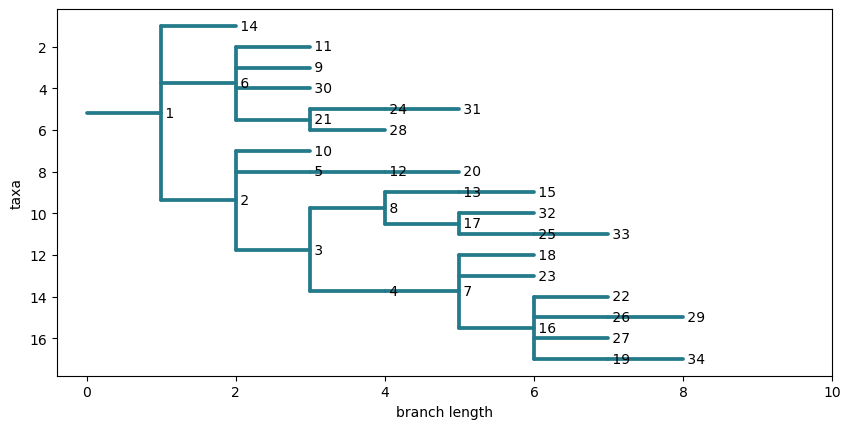

In [35]:
from Bio import Phylo
from Bio.Phylo.BaseTree import Tree, Clade
import matplotlib.pyplot as plt

# Convert DendroPy nodes into Biopython clades
# Direct conversion preseverse numeric IDs, including ancestor labels.
clades = {
    node: Clade(
        name=node.label or (node.taxon.label if node.taxon else None),
        branch_length=node.edge_length or 1
    )
    for node in tree.preorder_node_iter()
}

for node, clade in clades.items():
    clade.clades = [
        clades[child] for child in node.child_node_iter()
    ]

plot_tree = Tree(root=clades[tree.seed_node], rooted=True)
plot_tree.ladderize() # order branches by descendant count

# Stylying
plot_tree.root.color = "#237A8A"
plot_tree.root.width = 1.8

# Increase figure height with the number of leaves.
n_tips = plot_tree.count_terminals()
fig, ax = plt.subplots(figsize=(10, max(4, 0.28 * n_tips)))

Phylo.draw(
    plot_tree,
    axes=ax,
    do_show=False,
    show_confidence = False,
    label_func = lambda c: c.name,
)
plt.show()

In [32]:
n_tips

17